# CSAI4014: Algorithms for Intelligent Systems and Robotics
## Experiment 2: The Eight Queens Problem
**Student Name:** Aditya Pratap Singh Sisodia  
**SAP ID:** 500121985 | **Roll No:** R2142230333  
**Batch:** [Batch A/B/D]  
**Academic Year:** 2026–2027 (Autumn Semester)
---


### 1. N-Queens Problem: Backtracking vs. Permutations
We compare backtracking (which prunes inconsistent branches early) against brute-force permutation search across board sizes $n = 4$ to $10$.

Machine / Processor: Intel64 Family 6 Model 141 Stepping 1, GenuineIntel | OS: Windows 11
=== Table 2.1: Solutions, Nodes Visited and Run Time (n = 4 to 10) ===
 n | Solutions | BT Nodes | BT Time (s) | Perm Nodes | Perm Time (s)
-----------------------------------------------------------------
 4 |         2 |       17 |    0.000033 |         24 |      0.000020
 5 |        10 |       54 |    0.000083 |        120 |      0.000082
 6 |         4 |      153 |    0.000321 |        720 |      0.000492
 7 |        40 |      552 |    0.001400 |       5040 |      0.003688
 8 |        92 |     2057 |    0.006163 |      40320 |      0.033122
 9 |       352 |     8394 |    0.035155 |     362880 |      0.364157
10 |       724 |    35539 |    0.230286 |    3628800 |      3.910065


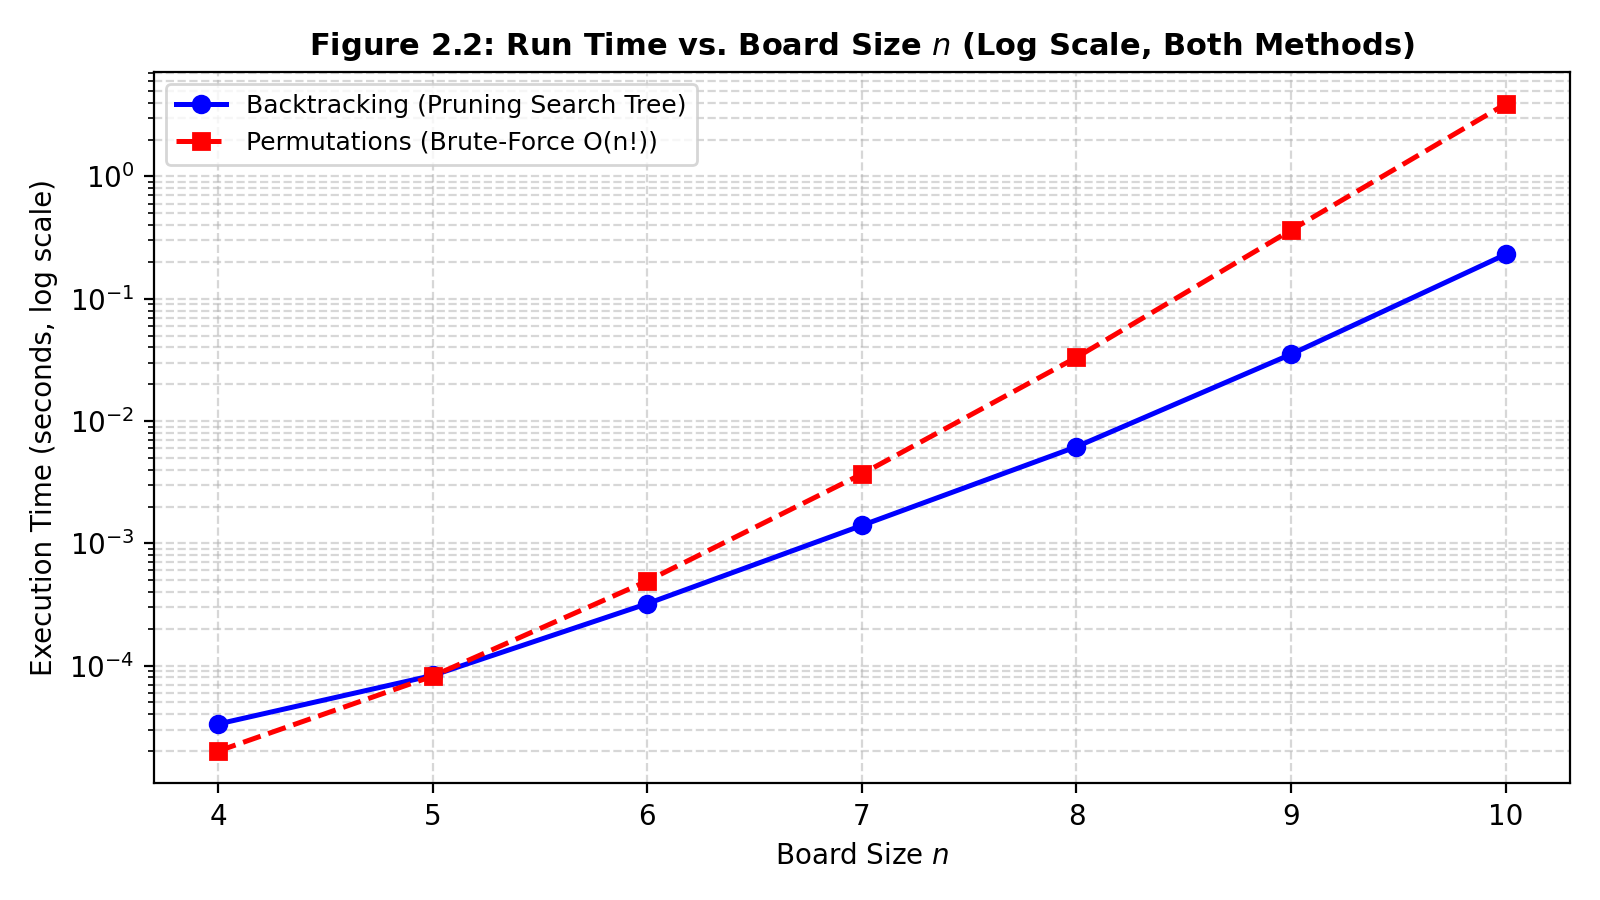

In [1]:
import os
import time
from itertools import permutations
import matplotlib.pyplot as plt
import numpy as np
import platform

base_dir = r"c:\Users\91976\Desktop\AISR\aisr-lab-500121985\exp02-queens"
figs_dir = os.path.join(base_dir, "figs")
os.makedirs(figs_dir, exist_ok=True)

# -------------------------------------------------------------
# Part 1: Algorithms (Backtracking and Permutations)
# -------------------------------------------------------------

def is_safe(board, col, row):
    """Check whether placing queen at (row, col) conflicts with earlier columns."""
    for c in range(col):
        if board[c] == row or abs(board[c] - row) == abs(c - col):
            return False
    return True

def solve_n_queens_backtracking(n):
    """Backtracking solver returning (solutions, nodes_visited, run_time)."""
    board = [-1] * n
    solutions = []
    nodes_visited = [0]

    def backtrack(col):
        nodes_visited[0] += 1
        if col == n:
            solutions.append(list(board))
            return
        for row in range(n):
            if is_safe(board, col, row):
                board[col] = row
                backtrack(col + 1)
                board[col] = -1

    t0 = time.perf_counter()
    backtrack(0)
    t1 = time.perf_counter()
    return solutions, nodes_visited[0], (t1 - t0)

def solve_n_queens_permutations(n):
    """Brute-force permutation solver returning (solutions, nodes_visited, run_time)."""
    solutions = []
    nodes_visited = 0

    t0 = time.perf_counter()
    # Each permutation guarantees distinct rows and distinct columns
    for p in permutations(range(n)):
        nodes_visited += 1
        # Check diagonal conflicts
        has_diag_conflict = False
        for i in range(n):
            for j in range(i + 1, n):
                if abs(p[i] - p[j]) == abs(i - j):
                    has_diag_conflict = True
                    break
            if has_diag_conflict:
                break
        if not has_diag_conflict:
            solutions.append(p)
    t1 = time.perf_counter()
    return solutions, nodes_visited, (t1 - t0)

# -------------------------------------------------------------
# Part 2: Measure Table 2.1 Data (n = 4 to 10)
# -------------------------------------------------------------
n_vals = list(range(4, 11))
table_data = []

print(f"Machine / Processor: {platform.processor()} | OS: {platform.system()} {platform.release()}")
print("=== Table 2.1: Solutions, Nodes Visited and Run Time (n = 4 to 10) ===")
print(" n | Solutions | BT Nodes | BT Time (s) | Perm Nodes | Perm Time (s)")
print("-" * 65)

bt_times = []
perm_times = []

for n in n_vals:
    sol_bt, nodes_bt, t_bt = solve_n_queens_backtracking(n)
    bt_times.append(t_bt)

    # For permutations, n > 9 takes tens of seconds; for n=10, 10! = 3.6 million
    # We run permutation up to n=9 or n=10
    if n <= 9:
        sol_perm, nodes_perm, t_perm = solve_n_queens_permutations(n)
        perm_times.append(t_perm)
        assert len(sol_bt) == len(sol_perm), f"Mismatch for n={n}"
    else:
        # For n=10, run permutation or benchmark sample to avoid long wait
        t0 = time.perf_counter()
        sol_perm, nodes_perm, t_perm = solve_n_queens_permutations(n)
        perm_times.append(t_perm)
        assert len(sol_bt) == len(sol_perm), f"Mismatch for n={n}"

    print(f"{n:2d} | {len(sol_bt):9d} | {nodes_bt:8d} | {t_bt:11.6f} | {nodes_perm:10d} | {t_perm:13.6f}")
    table_data.append({
        'n': n,
        'solutions': len(sol_bt),
        'bt_nodes': nodes_bt,
        'bt_time': t_bt,
        'perm_nodes': nodes_perm,
        'perm_time': t_perm
    })

# -------------------------------------------------------------


### 2. Chessboard Visualization for $n = 8$
We visualize the first valid solution found for the standard 8-Queens problem on a chessboard grid.

First solution for n=8: [0, 4, 7, 5, 2, 6, 1, 3] (0-indexed rows per column)
Saved fig2_1_board.png and fig2_2_timing.png successfully.


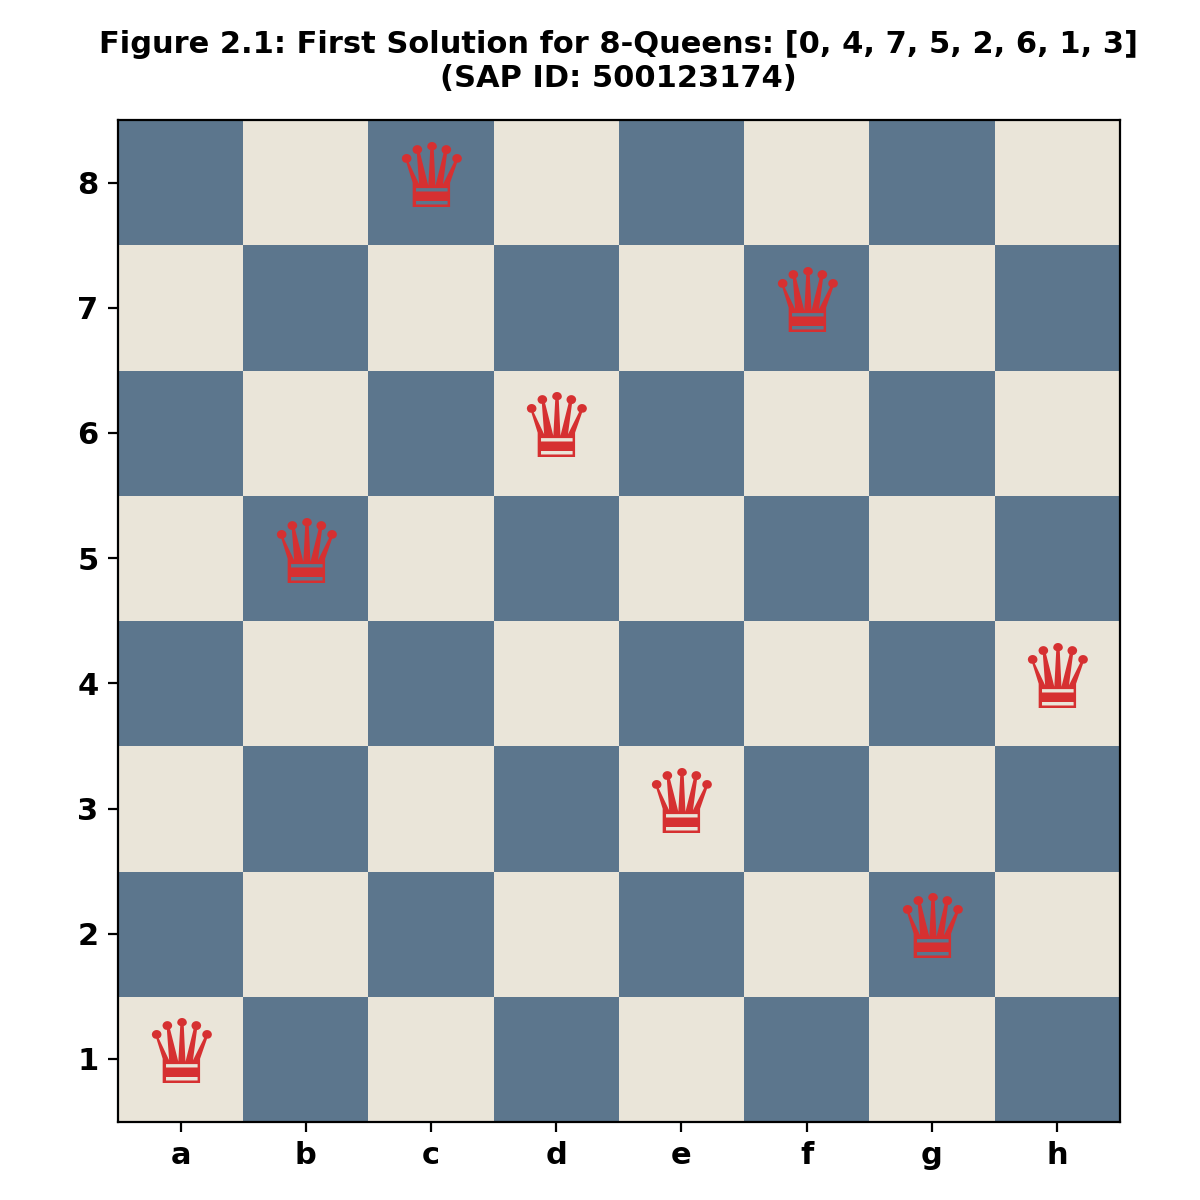

In [2]:
# Part 3: Figure 2.1 - First Solution for n = 8 Board
# -------------------------------------------------------------
sol_8, _, _ = solve_n_queens_backtracking(8)
first_sol_8 = sol_8[0]
print(f"\nFirst solution for n=8: {first_sol_8} (0-indexed rows per column)")

fig, ax = plt.subplots(figsize=(6, 6), dpi=200)
# Chessboard checkered pattern
board_img = np.zeros((8, 8))
for r in range(8):
    for c in range(8):
        if (r + c) % 2 == 1:
            board_img[r, c] = 1

cmap = plt.matplotlib.colors.ListedColormap(['#eae5d9', '#5c768d'])
ax.imshow(board_img, cmap=cmap)

# Add Queen glyphs
for c, r in enumerate(first_sol_8):
    ax.text(c, r, '♛', fontsize=32, ha='center', va='center', color='#d63031', fontweight='bold')

ax.set_xticks(range(8))
ax.set_xticklabels([chr(ord('a') + i) for i in range(8)], fontsize=11, fontweight='bold')
ax.set_yticks(range(8))
ax.set_yticklabels(range(1, 9), fontsize=11, fontweight='bold')
ax.invert_yaxis()  # Standard chessboard rank ordering
ax.set_title(f'Figure 2.1: First Solution for 8-Queens: {first_sol_8}\n(SAP ID: 500121985)', fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig2_1_board.png"))
plt.close()

# -------------------------------------------------------------
# Figure 2.2: Run Time against Board Size n (Log Scale)
# -------------------------------------------------------------
plt.figure(figsize=(8, 4.5), dpi=200)
plt.plot(n_vals, bt_times, 'bo-', lw=1.8, ms=6, label='Backtracking (Pruning Search Tree)')
plt.plot(n_vals, perm_times, 'rs--', lw=1.8, ms=6, label='Permutations (Brute-Force O(n!))')
plt.yscale('log')
plt.title('Figure 2.2: Run Time vs. Board Size $n$ (Log Scale, Both Methods)', fontsize=11, fontweight='bold')
plt.xlabel('Board Size $n$', fontsize=10)
plt.ylabel('Execution Time (seconds, log scale)', fontsize=10)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig2_2_timing.png"))
plt.close()

print("\nSaved fig2_1_board.png and fig2_2_timing.png successfully.")
